# Dimensionality reduction

Features in een dataset noemen we ook wel eens dimensies. Bekijk volgend voorbeeldje van een dataset met 3 punten, met elk 3 dimensies:

| Dataset   | Feature 1 | Feature 2 | Feature 3 |
|--------------|----------|----------|----------|
| datapoint1   |    0     |    1     |    1     |
| datapoint2   |   0.5    |   0.5    |   0.5    |
| datapoint3   |    0     |    0     |    0     |
| datapoint4   |    1     |    0     |    0     |
| datapoint5   |    0.3     |    0.6     |    0.8     |


Deze kunnen we plotten in 3D:

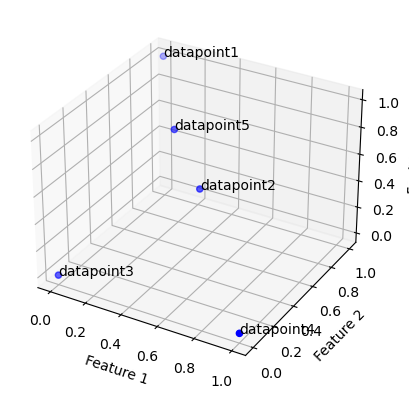

In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Data
data = {
    'datapoint1': (0, 1, 1),
    'datapoint2': (0.5, 0.5, 0.5),
    'datapoint3': (0, 0, 0),
    'datapoint4': (1, 0, 0),
    'datapoint5': (0.3, 0.6, 0.8)
}

# Extract data 
data_points = list(data.keys())
x_values, y_values, z_values = zip(*data.values())

# 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot data punten
ax.scatter(x_values, y_values, z_values, c='b', marker='o')

# Labels
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')

# Data labels
for i, data_point in enumerate(data_points):
    ax.text(x_values[i], y_values[i], z_values[i], data_point)

plt.show()

Soms zijn er zoveel features, dat het zinvol is om onder het motto '*less is more*' data weg te doen. Deze compressie is enerzijds nuttig om ruimte te besparen, maar kan ook een stap zijn vooraleer verdere algoritmes toe te passen.

## Labeled faces in the Wild dataset (LFW)
We gebruiken deze gekende dataset in een poging om data te compresseren. (http://vis-www.cs.umass.edu/lfw/)

In [2]:
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from time import time
import matplotlib.pyplot as plt


In [3]:
people = fetch_lfw_people(min_faces_per_person=5, resize=1)
n_samples, h, w = people.images.shape
print("Voorbeeld set: ",n_samples, "Hoogte and breedte: ",h, w)

Voorbeeld set:  5985 Hoogte and breedte:  125 94


In [4]:
125*94

11750

We kijken hoe een typisch datapunt eruitziet door een willekeurig exemplaar te plotten

We bekijken persoon met index 3319


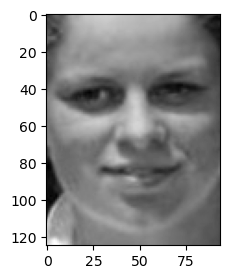

In [5]:
import random


def plot_person(i):
    plt.figure(figsize=(4,3))
    plt.imshow(people.images[i].reshape((h,w)), cmap='gray')

random_integer = random.randint(0, n_samples - 1)
index_kim = 3319
print("We bekijken persoon met index %d" % index_kim)
plot_person(index_kim)

(Ter info, Kim Clijsters is persoon met onder andere index 3319)

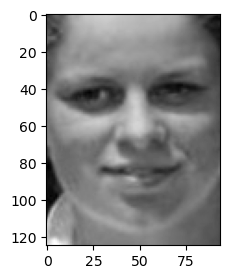

In [6]:
plot_person(3319)

Data even opnieuw goed zetten vooraleer PCA toe te passen

In [7]:
people.images[0].reshape(-1).shape

(11750,)

In [8]:
X = people.data
n_features = X.shape[1]

y = people.target
target_names = people.target_names
n_classes = target_names.shape[0]

In [9]:
len(target_names)

423

In [10]:
print("Totale dataset grootte:")
print("n_samples: %d" % n_samples)
print("n_features: %d" % n_features)
print("n_classes: %d" % n_classes)

Totale dataset grootte:
n_samples: 5985
n_features: 11750
n_classes: 423


We gaan naar goede gewoonte de data splitten

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = 0.75, random_state = 42)

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Dimensionality reduction

In [13]:
n_components = 200

print("Datareductie tot %d generieke gezichten vanuit %d originele gezichten" % (n_components, X_train_scaled.shape[0]))
t0 = time()
pca = PCA(n_components = n_components, svd_solver = 'randomized', whiten=True).fit(X_train_scaled) # randomized is VEEL sneller dan een full solver
print("Klaar in %0.3fs" % (time() - t0))

Datareductie tot 200 generieke gezichten vanuit 4488 originele gezichten
Klaar in 2.634s


We kijken nu naar de principale componenten, die zijn het resultaat van dit PCA-algoritme. We krijgen het aantal gevraagde componenten terug, en elke component is een vector. Als we dit terug willen omzetten naar een foto, moeten we `rehape` opnieuw gebruiken:

In [14]:
eigenfaces = pca.components_.reshape((n_components, h, w))

In [15]:
eigenfaces[0].shape

(125, 94)

In [16]:
# data transformeren

t0 = time()
X_train_pca = pca.transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Klaar in %0.3fs" % (time() - t0))

Klaar in 0.435s


In [17]:
X_train.shape
X_train_pca.shape

(4488, 200)

Hoe zien deze eigenfaces eruit ? Het zijn generatieve 'gezichten', waaruit we alsof het bouwblokken zijn, andere gezichten kunnen samenstellen. De eerste 9 *eigenfaces* zien er als volgt uit:

In [18]:
def plot_gallery(images, titles, h, w, n_row=3, n_col=3):
    """Helper functie voor een galerij van portretten"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

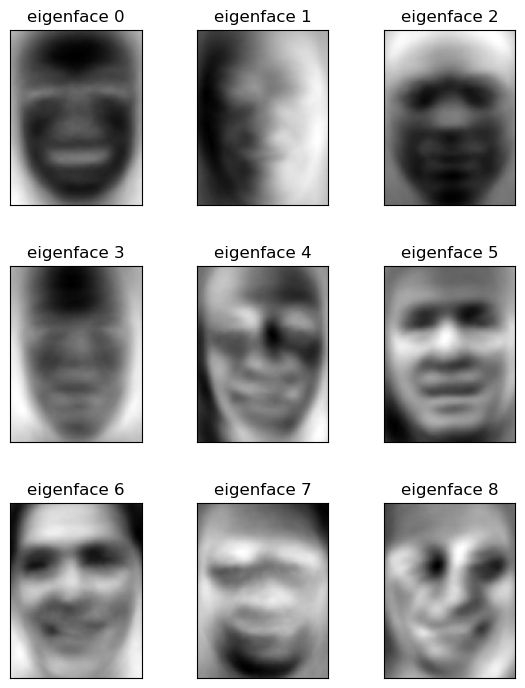

In [19]:
#de eigenfaces labeltjes om te plotten
eigenfaces_titels = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_gallery(eigenfaces, eigenfaces_titels, h,w)


Deze generieke gezichten kunnen worden gebruikt om voor een bepaalde foto een benadering terug te geven. Dit wordt gedaan door een foto te bekijken als de som van een aantal eigenfaces. Op die manier moet je geen individuele pixels meer bijhouden, maar enkel de coëfficiënten van de eigenfaces. Laten we kijken hoe dit er uitziet:

In [20]:
X_train_scaled[0].shape

(11750,)

In [21]:
#even zoeken naar Kim Clijsters in de training dataset
import numpy as np
target_clijsters = np.where(people.target_names == "Kim Clijsters")[0][0]

indices_clijsters = np.where(y_train == target_clijsters)[0]
index_clijsters = indices_clijsters[2]

In [22]:
target_clijsters

218

In X_train_pca zitten de coëfficiënten om met behulp van de eigenfaces terug het originele beeld (gecompresseerd!) te bereiken:

In [23]:
X_train_pca[index_clijsters]

array([ 0.8849074 , -0.16581544,  0.1474152 ,  1.061167  , -1.2165093 ,
        0.07094125, -1.188078  , -0.93625665, -0.19830598,  0.5099924 ,
        0.69465005,  0.5639408 , -0.07444675,  0.16937725,  1.0115817 ,
       -0.9728501 , -0.07107148, -1.0795214 , -1.6454161 ,  1.2046298 ,
       -0.7993664 ,  0.31643805, -0.3409114 ,  0.8830505 ,  0.152438  ,
       -0.35201097,  0.05147859, -1.1293732 , -0.831719  , -0.68033457,
       -0.6734802 ,  1.4333093 ,  0.03496137, -0.21614245, -0.51643306,
       -1.6034139 ,  0.16281691, -0.3408087 , -1.0104423 , -0.2677309 ,
       -1.6249855 , -0.78399336, -0.08166978,  0.87119716,  1.3650995 ,
       -0.8422036 ,  1.2502878 , -0.7329678 ,  1.2542558 ,  0.7166899 ,
        0.5917729 , -0.6591804 , -0.9923933 , -0.3751058 ,  1.0985255 ,
        0.14522965, -0.30864218, -0.8567482 ,  0.2196786 ,  0.54992586,
       -0.3855723 ,  1.7398516 , -0.26751074, -0.23463383, -0.23302495,
       -1.4817204 , -0.804207  ,  0.16946748, -0.5498295 ,  0.13

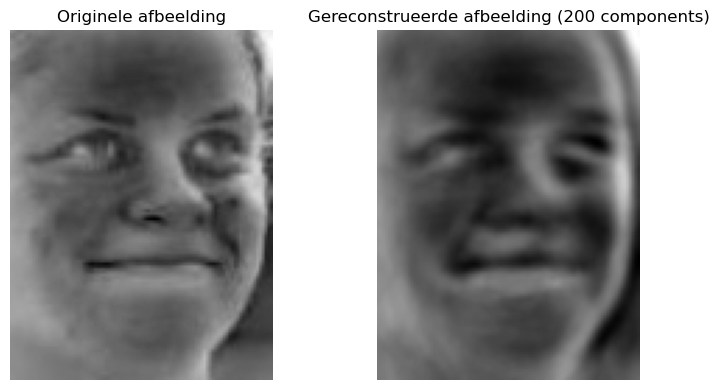

In [24]:

reconstructed_X = pca.inverse_transform(X_train_pca)
reconstructed_image = reconstructed_X[index_clijsters].reshape((h,w))
original_image = X_train_scaled[index_clijsters].reshape((h,w))

# Plot the original and reconstructed images
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(original_image, cmap='gray')
plt.title('Originele afbeelding')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image, cmap='gray')
plt.title('Gereconstrueerde afbeelding ({} components)'.format(n_components))
plt.axis('off')

plt.tight_layout()
plt.show()



### Datareductie
In de originele, volledige dataset hadden we 5985 afbeeldingen, van telkens 125*94 pixels. Dat zijn in totaal 70 323 750 pixels om op te slaan. In de nieuwe setup hebben we
- 200 eigenfaces, dus 200 * (125 * 94) = 2 350 000  pixels om op te slaan
- Voor elk prentje hebben we nu 200 coëfficiënten, 1 per eigenfaces, omdat elke afbeelding nu een unieke som is van dezelfde eigenfaces:
$$ 1\phantom{x} \mathrm{Foto} = \sum_{i=1}^{200} c_{i} \cdot \mathrm{eigenface}_i  $$
- In totaal hebben we dus, voor 5985 afbeeldingen, 5985 * 200 coeëfficiënten nodig, en ook de 2350000 pixels van de eigenfaces. Dit is in totaal 3547000 getallen om bij te houden.

Dit betekent dat de gereduceerde afbeeldingen slechts $ \frac{3547000}{70323750} \approx 0.0504$ oftewel 5% van de plaats innemen als de originele dataset.

In [25]:
((200 * 125 * 94) + (5985 * 200)) / (5985 * 125*94)

0.05043815211788336

### Voorspelling van een andere afbeelding

In [26]:
from time import time
import logging
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA
from sklearn.svm import SVC

In [27]:
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=1)

# dimensies straks nodig voor plotten
n_samples, h, w = lfw_people.images.shape
X = lfw_people.data
n_features = X.shape[1]

# Label is naam van de persoon
y = lfw_people.target
target_names = lfw_people.target_names
n_classes = target_names.shape[0]

print("Grootte dataset:")
print("n_samples: %d" % n_samples)
print("n_features: %d" % n_features)
print("n_classes: %d" % n_classes)


# Split  training set, a test set :  stratified k fold
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y)

# PCA met 150 componenten
n_components = 150

print("Meest voorkomende top %d eigenfaces van %d faces"
      % (n_components, X_train.shape[0]))
t0 = time()
pca = PCA(n_components=n_components, svd_solver='auto', whiten=True).fit(X_train)
print("done in %0.3fs" % (time() - t0))

eigenfaces = pca.components_.reshape((n_components, h, w))

print("Projecteer input data naar de orthonormale basis")
t0 = time()
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print("done in %0.3fs" % (time() - t0))

Grootte dataset:
n_samples: 1288
n_features: 11750
n_classes: 7
Meest voorkomende top 150 eigenfaces van 966 faces
done in 0.368s
Projecteer input data naar de orthonormale basis
done in 0.063s


In [28]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC

print("Trainen van classifier op training set")
t0 = time()
param_grid = {
    "C": loguniform(1e3, 1e5),
    "gamma": loguniform(1e-4, 1e-1),
}
clf = RandomizedSearchCV(
    SVC(kernel="rbf", class_weight="balanced"), param_grid, n_iter=10
)
clf = clf.fit(X_train_pca, y_train)
print("done in %0.3fs" % (time() - t0))
print("Best estimator met grid search:")
print(clf.best_estimator_)

Trainen van classifier op training set
done in 3.844s
Best estimator met grid search:
SVC(C=4072.108122536026, class_weight='balanced', gamma=0.0025307838911808826)


In [29]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("Mensen voorspellen op basis van de test set")
t0 = time()
y_pred = clf.predict(X_test_pca)
print("done in %0.3fs" % (time() - t0))

print(classification_report(y_test, y_pred, target_names=target_names))

Mensen voorspellen op basis van de test set
done in 0.026s
                   precision    recall  f1-score   support

     Ariel Sharon       0.87      0.68      0.76        19
     Colin Powell       0.79      0.92      0.85        59
  Donald Rumsfeld       0.78      0.83      0.81        30
    George W Bush       0.87      0.91      0.89       133
Gerhard Schroeder       0.95      0.74      0.83        27
      Hugo Chavez       0.93      0.72      0.81        18
       Tony Blair       0.82      0.75      0.78        36

         accuracy                           0.85       322
        macro avg       0.86      0.79      0.82       322
     weighted avg       0.85      0.85      0.85       322



Sommige namen kwamen niet voor in de training set. Dit geeft een probleem tijdens het testen. Dat moeten we oplossen.

In [30]:
test_classes = np.unique(y_test)
test_target_names = [target_names[i] for i in test_classes]

Tijd voor een eerste analyse

In [31]:
print(classification_report(y_test, y_pred, target_names=test_target_names))
ConfusionMatrixDisplay.from_estimator(
    clf, X_test_pca, y_test, display_labels=test_target_names, xticks_rotation="vertical"
)
plt.tight_layout()
plt.show()

                   precision    recall  f1-score   support

     Ariel Sharon       0.87      0.68      0.76        19
     Colin Powell       0.79      0.92      0.85        59
  Donald Rumsfeld       0.78      0.83      0.81        30
    George W Bush       0.87      0.91      0.89       133
Gerhard Schroeder       0.95      0.74      0.83        27
      Hugo Chavez       0.93      0.72      0.81        18
       Tony Blair       0.82      0.75      0.78        36

         accuracy                           0.85       322
        macro avg       0.86      0.79      0.82       322
     weighted avg       0.85      0.85      0.85       322



NameError: name 'ConfusionMatrixDisplay' is not defined

Helper functie om de gallerij te plotten

In [32]:
def plot_gallery(images, titles, h, w, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=0.01, right=0.99, top=0.90, hspace=0.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

We printen nu het resultaat van een stukje van de test set

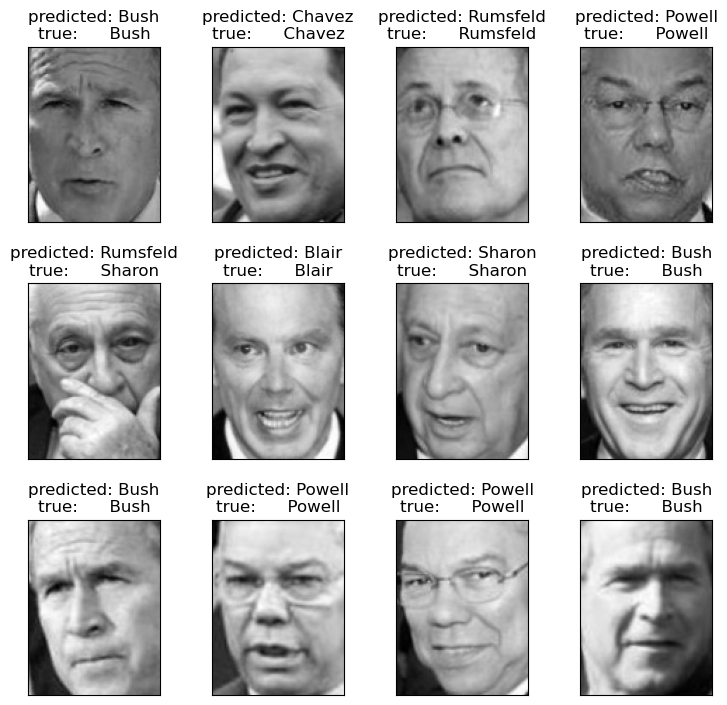

In [33]:
def title(y_pred, y_test, target_names, i):
    pred_name = target_names[y_pred[i]].rsplit(" ", 1)[-1]
    true_name = target_names[y_test[i]].rsplit(" ", 1)[-1]
    return "predicted: %s\ntrue:      %s" % (pred_name, true_name)


prediction_titles = [
    title(y_pred, y_test, target_names, i) for i in range(y_pred.shape[0])
]

plot_gallery(X_test, prediction_titles, h, w)

Plot de belangrijkste eigenfaces

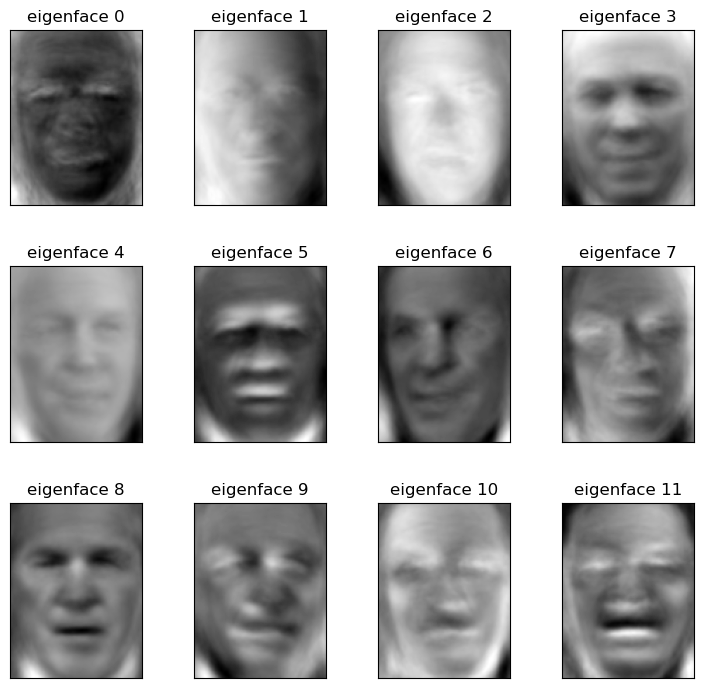

In [34]:
eigenface_titles = ["eigenface %d" % i for i in range(eigenfaces.shape[0])]
plot_gallery(eigenfaces, eigenface_titles, h, w)

### Bewaarde variantie
Hoeveel van de variatie is er nu bewaard gebleven ?

In [35]:
saved_variance = sum(pca.explained_variance_ratio_)
print("In totaal is er %f percent variantie van de dataset bewaard gebleven." % (100 * saved_variance))

In totaal is er 93.016648 percent variantie van de dataset bewaard gebleven.


## PCA op een simpeler voorbeeld

In [36]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "dim_reduction"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

Een 3D dataset (de code is ter illustratie, dit moet je niet zelf kunnen):

In [37]:
import numpy as np
from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))  # initalisatie 3D dataset
np.random.seed(42)
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi  # onevenwichtige verdeling
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # dit tekent een ovaal
X += 0.28 * np.random.randn(m, 3)  # ruis toevoegen
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]  # opschuiven , weg van het centrum

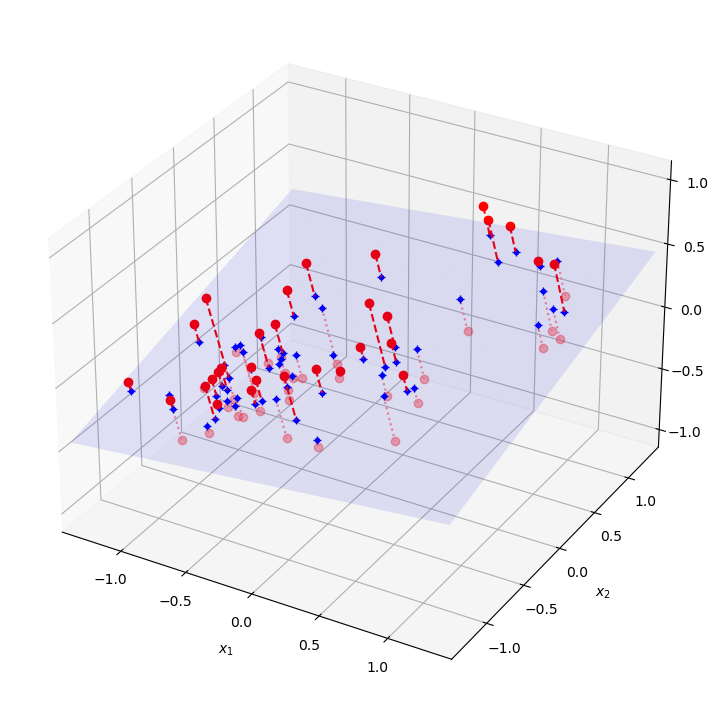

In [38]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2) # we gaan projecteren op 2 dimensies
X2D = pca.fit_transform(X)  # dataset reduced to 2D
X3D_inv = pca.inverse_transform(X2D)  # 3D position of the projected samples
X_centered = X - X.mean(axis=0)

#dit is hoe achterliggend de principale waardes worden bepaald. Die bevinden zich op de diagonaal van de matrix S
U, s, Vt = np.linalg.svd(X_centered)

#voorbereiding voor 3D plots
axes = [-1.4, 1.4, -1.4, 1.4, -1.1, 1.1]
x1, x2 = np.meshgrid(np.linspace(axes[0], axes[1], 10),
                     np.linspace(axes[2], axes[3], 10))

#met behulp van Vt kun je het vlak maken waarop wordt geprojecteerd
w1, w2 = np.linalg.solve(Vt[:2, :2], Vt[:2, 2])  # coëfficiënten van het vlak waarop we gaan projecteren
z = w1 * (x1 - pca.mean_[0]) + w2 * (x2 - pca.mean_[1]) - pca.mean_[2]  # vlak


X3D_above = X[X[:, 2] >= X3D_inv[:, 2]]  # items boven het vlak
X3D_below = X[X[:, 2] < X3D_inv[:, 2]]  # items onder het vlak

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

# eerst plotten van punten onder het vlak.
ax.plot(X3D_below[:, 0], X3D_below[:, 1], X3D_below[:, 2], "ro", alpha=0.3)
for i in range(m):
    if X[i, 2] < X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], ":", color="#F88")

ax.plot_surface(x1, x2, z, alpha=0.1, color="b")  # projection plane
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b+")  # projected samples
ax.plot(X3D_inv[:, 0], X3D_inv[:, 1], X3D_inv[:, 2], "b.")

# plotten van punten boven het vlak
for i in range(m):
    if X[i, 2] >= X3D_inv[i, 2]:
        ax.plot([X[i][0], X3D_inv[i][0]],
                [X[i][1], X3D_inv[i][1]],
                [X[i][2], X3D_inv[i][2]], "r--")

ax.plot(X3D_above[:, 0], X3D_above[:, 1], X3D_above[:, 2], "ro")

# assen een naam geven en netjes instellen
def set_xyz_axes(ax, axes):
    ax.xaxis.set_rotate_label(False)
    ax.yaxis.set_rotate_label(False)
    ax.zaxis.set_rotate_label(False)
    ax.set_xlabel("$x_1$", labelpad=8, rotation=0)
    ax.set_ylabel("$x_2$", labelpad=8, rotation=0)
    ax.set_zlabel("$x_3$", labelpad=8, rotation=0)
    ax.set_xlim(axes[0:2])
    ax.set_ylim(axes[2:4])
    ax.set_zlim(axes[4:6])

set_xyz_axes(ax, axes)
ax.set_zticks([-1, -0.5, 0, 0.5, 1])

save_fig("dataset_3d_plot", tight_layout=False)
plt.show()

Deze dataset hebben we dus gereduceerd van 3D naar 2D. PCA met *n* componenten gaat een dataset steeds reduceren door te **projecteren** op een hypervlak van *n* dimensies. PCA kiest ook altijd precies dat hypervlak uit dat de meeste informatie bewaart.

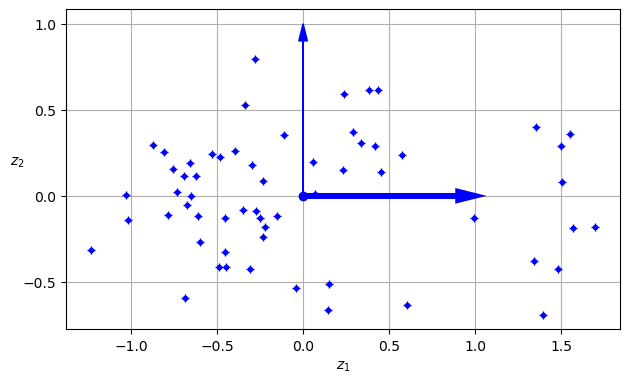

In [39]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, aspect='equal')
ax.plot(X2D[:, 0], X2D[:, 1], "b+")
ax.plot(X2D[:, 0], X2D[:, 1], "b.")
ax.plot([0], [0], "bo")
ax.arrow(0, 0, 1, 0, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=4)
ax.arrow(0, 0, 0, 1, head_width=0.05, length_includes_head=True,
         head_length=0.1, fc='b', ec='b', linewidth=1)
ax.set_xlabel("$z_1$")
ax.set_yticks([-0.5, 0, 0.5, 1])
ax.set_ylabel("$z_2$", rotation=0)
ax.set_axisbelow(True)
ax.grid(True)
save_fig("dataset_2d_plot")

### Scikit Learn syntax

In [40]:
import numpy as np
from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))  # initalisatie 3D dataset
np.random.seed(42)
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi  # onevenwichtige verdeling
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # dit tekent een ovaal
X += 0.28 * np.random.randn(m, 3)  # ruis toevoegen
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]  # opschuiven , weg van het centrum

In [41]:
# met scikit learn
n_components = 2  # 2D
pca = PCA(n_components=n_components)
X_reduced = pca.fit_transform(X)

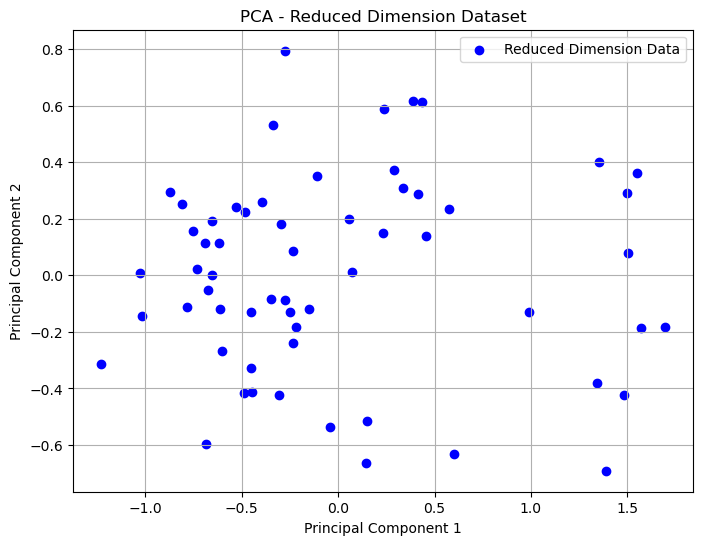

In [42]:
import matplotlib.pyplot as plt
# Plot de lager gedimensioneerde dataset
plt.figure(figsize=(8, 6))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c='b', marker='o', label='Reduced Dimension Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Reduced Dimension Dataset')
plt.legend()
plt.grid()
plt.show()

In [43]:
pca.explained_variance_ratio_

array([0.7578477 , 0.15186921])

In [44]:
sum(pca.explained_variance_ratio_)

0.9097169067325795

## Locally Linear Embedding (LLE)

In [45]:
from sklearn.datasets import make_swiss_roll

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)

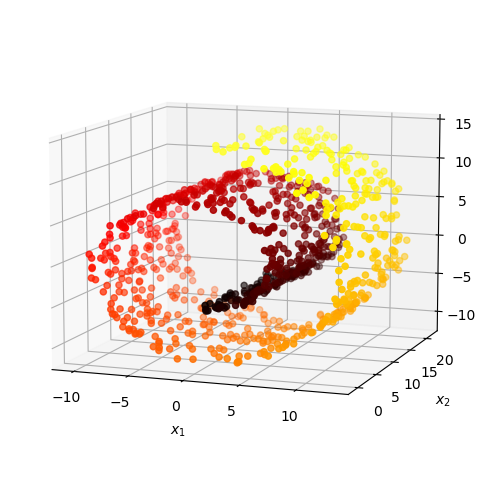

In [46]:
from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

axes = [-11.5, 14, -2, 23, -12, 15]

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_swiss[:, 0], X_swiss[:, 1], X_swiss[:, 2], c=t, cmap=darker_hot)
ax.view_init(10, -70)
set_xyz_axes(ax, axes)
save_fig("swiss_roll_plot")
plt.show()

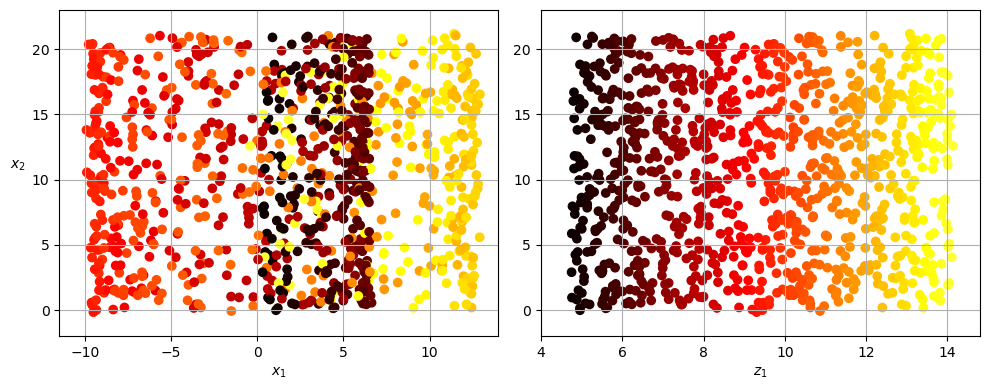

In [47]:
plt.figure(figsize=(10, 4))

plt.subplot(121)
plt.scatter(X_swiss[:, 0], X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis(axes[:4])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$", labelpad=10, rotation=0)
plt.grid(True)

plt.subplot(122)
plt.scatter(t, X_swiss[:, 1], c=t, cmap=darker_hot)
plt.axis([4, 14.8, axes[2], axes[3]])
plt.xlabel("$z_1$")
plt.grid(True)

save_fig("squished_swiss_roll_plot")
plt.show()

In [48]:
from sklearn.manifold import LocallyLinearEmbedding
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

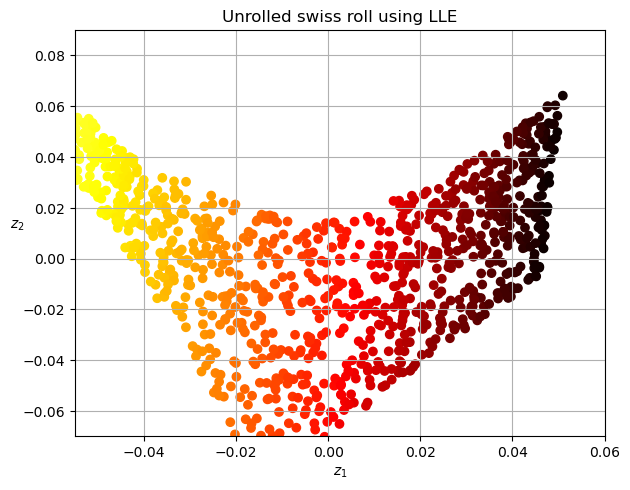

In [49]:
plt.scatter(X_unrolled[:, 0], X_unrolled[:, 1],
            c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.055, 0.060, -0.070, 0.090])
plt.grid(True)

save_fig("lle_unrolling_plot")
plt.title("Unrolled swiss roll using LLE")
plt.show()